# Netflix Movies and TV Shows — Exploratory Data Analysis

A full EDA project on the Netflix titles catalog: data cleaning, business-question analysis,
visualizations, and written insights.

**Dataset:** `netflix_titles.csv` (Netflix Movies and TV Shows, ~6,200 titles, sourced from Kaggle's
`shivamb/netflix-shows` dataset)


## 1. Load & Inspect the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

df = pd.read_csv('../dataset/netflix_titles.csv')
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China","September 9, 2019",2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,"September 9, 2016",2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,"September 8, 2018",2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob..."
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,"September 8, 2018",2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,"September 8, 2017",2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...


In [2]:
df.tail()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
6229,80000063,TV Show,Red vs. Blue,NaN,"Burnie Burns, Jason Saldaña, Gustavo Sorola, G...",United States,NaN,2015,NR,13 Seasons,"TV Action & Adventure, TV Comedies, TV Sci-Fi ...","This parody of first-person shooter games, mil..."
6230,70286564,TV Show,Maron,NaN,"Marc Maron, Judd Hirsch, Josh Brener, Nora Zeh...",United States,NaN,2016,TV-MA,4 Seasons,TV Comedies,"Marc Maron stars as Marc Maron, who interviews..."
6231,80116008,Movie,Little Baby Bum: Nursery Rhyme Friends,NaN,NaN,NaN,NaN,2016,NaN,60 min,Movies,Nursery rhymes and original music for children...
6232,70281022,TV Show,A Young Doctor's Notebook and Other Stories,NaN,"Daniel Radcliffe, Jon Hamm, Adam Godley, Chris...",United Kingdom,NaN,2013,TV-MA,2 Seasons,"British TV Shows, TV Comedies, TV Dramas","Set during the Russian Revolution, this comic ..."
6233,70153404,TV Show,Friends,NaN,"Jennifer Aniston, Courteney Cox, Lisa Kudrow, ...",United States,NaN,2003,TV-14,10 Seasons,"Classic & Cult TV, TV Comedies",This hit sitcom follows the merry misadventure...


In [3]:
df.shape

(6234, 12)

In [4]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6234 entries, 0 to 6233
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       6234 non-null   int64
 1   type          6234 non-null   str  
 2   title         6234 non-null   str  
 3   director      4265 non-null   str  
 4   cast          5664 non-null   str  
 5   country       5758 non-null   str  
 6   date_added    6223 non-null   str  
 7   release_year  6234 non-null   int64
 8   rating        6224 non-null   str  
 9   duration      6234 non-null   str  
 10  listed_in     6234 non-null   str  
 11  description   6234 non-null   str  
dtypes: int64(2), str(10)
memory usage: 584.6 KB


In [6]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,6234.0,NaN,NaN,NaN,76703679.319859,10942964.649885,247747.0,80035801.75,80163367.0,80244888.75,81235729.0
type,6234,2,Movie,4265,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,6234,6172,Love,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,4265,3301,"Raúl Campos, Jan Suter",18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,5664,5469,David Attenborough,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,5758,554,United States,2032,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,6223,1524,"January 1, 2020",122,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,6234.0,NaN,NaN,NaN,2013.35932,8.81162,1925.0,2013.0,2016.0,2018.0,2020.0
rating,6224,14,TV-MA,2027,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,6234,201,1 Season,1321,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data Cleaning

### 2.1 Check missing values

In [7]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})

,missing_count,missing_pct
director,1969,31.58
cast,570,9.14
country,476,7.64
date_added,11,0.18
rating,10,0.16
title,0,0.00
show_id,0,0.00
type,0,0.00
release_year,0,0.00
duration,0,0.00


### 2.2 Remove duplicates

In [8]:
dupes = df.duplicated().sum()
print(f"Duplicate rows: {dupes}")
df = df.drop_duplicates()

Duplicate rows: 0


### 2.3 Fill missing values

In [9]:
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')
df['rating'] = df['rating'].fillna(df['rating'].mode()[0])
df['date_added'] = df['date_added'].fillna(df['date_added'].mode()[0])
df.isnull().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

### 2.4 Convert date columns & fix dtypes

In [10]:
df['date_added'] = pd.to_datetime(df['date_added'].str.strip(), errors='coerce')
df['year_added'] = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month_name()
df['release_year'] = df['release_year'].astype(int)
df.dtypes

show_id                  int64
type                       str
title                      str
director                   str
cast                       str
country                    str
date_added      datetime64[us]
release_year             int64
rating                     str
duration                   str
listed_in                  str
description                str
year_added               int32
month_added                str
dtype: object

### 2.5 Rename columns for consistency

In [11]:
df = df.rename(columns={'listed_in': 'genres'})
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'genres', 'description',
       'year_added', 'month_added'],
      dtype='str')

### 2.6 Parse duration into separate numeric fields

In [12]:
df['duration_int'] = df['duration'].str.extract('(\\d+)').astype(float)
df['duration_type'] = df['duration'].str.extract('([a-zA-Z]+)')
df[['duration', 'duration_int', 'duration_type']].head()

,duration,duration_int,duration_type
0,90 min,90.0,min
1,94 min,94.0,min
2,1 Season,1.0,Season
3,1 Season,1.0,Season
4,99 min,99.0,min


## 3. Exploratory Data Analysis

### 3.1 Basic Questions

In [13]:
type_counts = df['type'].value_counts()
type_counts

type
Movie      4265
TV Show    1969
Name: count, dtype: int64

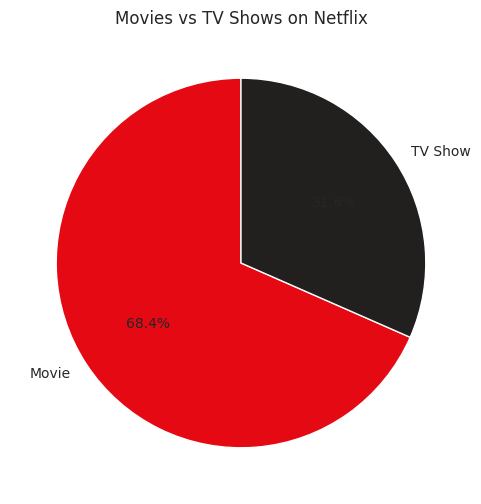

In [14]:
plt.figure(figsize=(6,6))
plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%',
        colors=['#E50914', '#221F1F'], startangle=90,
        wedgeprops={'edgecolor': 'white'})
plt.title('Movies vs TV Shows on Netflix')
plt.savefig('../images/type_pie.png', dpi=150, bbox_inches='tight')
plt.show()

**Insight:** Movies make up a much larger share of Netflix's catalog than TV Shows, suggesting Netflix has historically invested more heavily in film content than in serialized programming.

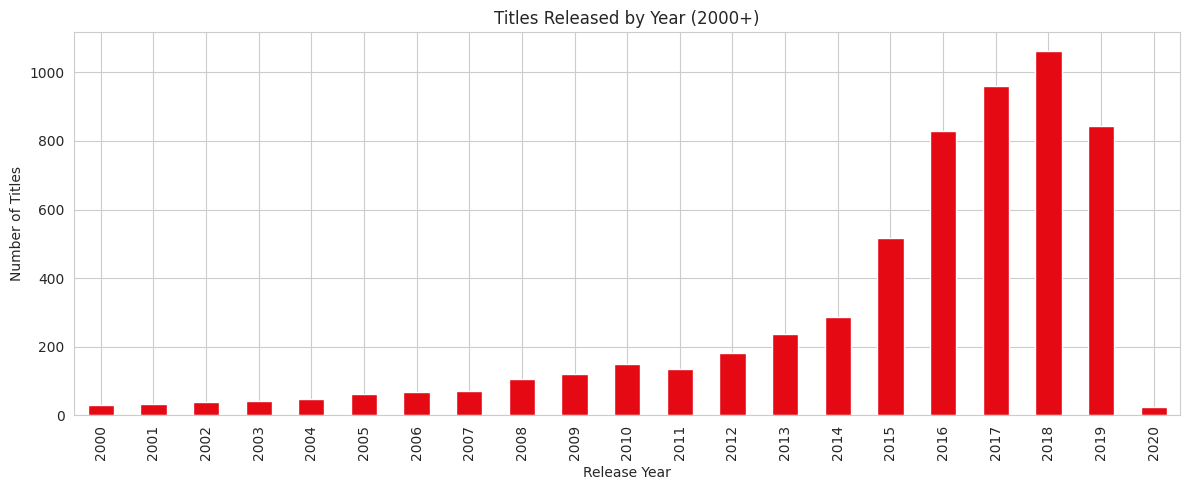

In [15]:
year_counts = df['release_year'].value_counts().sort_index()
plt.figure(figsize=(12,5))
year_counts[year_counts.index >= 2000].plot(kind='bar', color='#E50914')
plt.title('Titles Released by Year (2000+)')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.tight_layout()
plt.savefig('../images/releases_by_year.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
top_release_year = df['release_year'].value_counts().idxmax()
print(f"Year with most releases: {top_release_year}")

Year with most releases: 2018


**Insight:** Content releases climb steadily and peak in the late 2010s, reflecting Netflix's aggressive content-acquisition and original-production push during that period.

### 3.2 Country Analysis

In [17]:
countries = df['country'].str.split(', ').explode()
top_countries = countries[countries != 'Unknown'].value_counts().head(10)
top_countries

country
United States     2609
India              838
United Kingdom     601
Canada             318
France             271
Japan              231
Spain              178
South Korea        162
Germany            151
Mexico             129
Name: count, dtype: int64

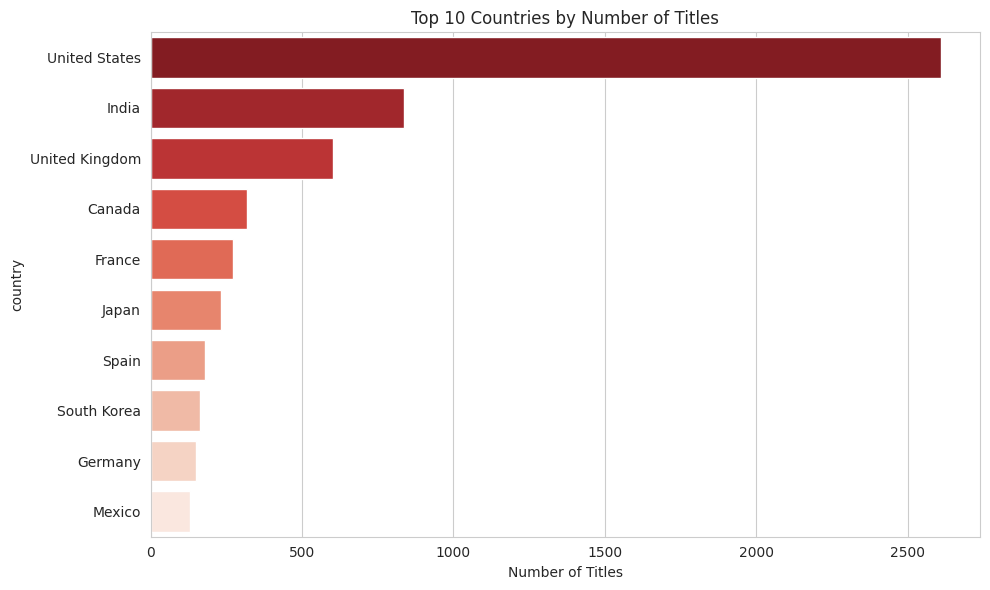

In [18]:
plt.figure(figsize=(10,6))
sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index,
            palette='Reds_r', legend=False)
plt.title('Top 10 Countries by Number of Titles')
plt.xlabel('Number of Titles')
plt.tight_layout()
plt.savefig('../images/top_countries.png', dpi=150, bbox_inches='tight')
plt.show()

**Insight:** The United States and India dominate content production by a wide margin, with the US contributing the largest share overall — consistent with Netflix's origins and largest subscriber base.

### 3.3 Genre Analysis

In [19]:
genres = df['genres'].str.split(', ').explode()
top_genres = genres.value_counts().head(10)
bottom_genres = genres.value_counts().tail(10)
top_genres

genres
International Movies      1927
Dramas                    1623
Comedies                  1113
International TV Shows    1001
Documentaries              668
TV Dramas                  599
Action & Adventure         597
Independent Movies         552
TV Comedies                436
Thrillers                  392
Name: count, dtype: int64

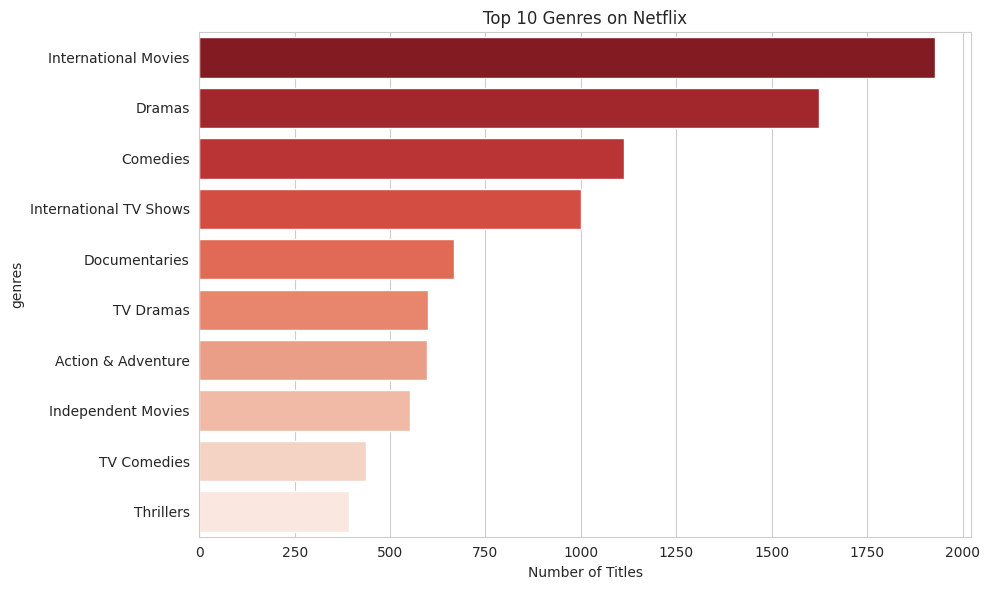

In [20]:
plt.figure(figsize=(10,6))
sns.barplot(x=top_genres.values, y=top_genres.index, hue=top_genres.index,
            palette='Reds_r', legend=False)
plt.title('Top 10 Genres on Netflix')
plt.xlabel('Number of Titles')
plt.tight_layout()
plt.savefig('../images/top_genres.png', dpi=150, bbox_inches='tight')
plt.show()

**Insight:** International Movies, Dramas, and Comedies dominate the catalog, showing Netflix's strategy of balancing broad, mainstream genres with region-specific content to appeal to a global audience.

### 3.4 Rating Analysis

In [21]:
rating_counts = df['rating'].value_counts()
rating_counts

rating
TV-MA       2037
TV-14       1698
TV-PG        701
R            508
PG-13        286
NR           218
PG           184
TV-Y7        169
TV-G         149
TV-Y         143
TV-Y7-FV      95
G             37
UR             7
NC-17          2
Name: count, dtype: int64

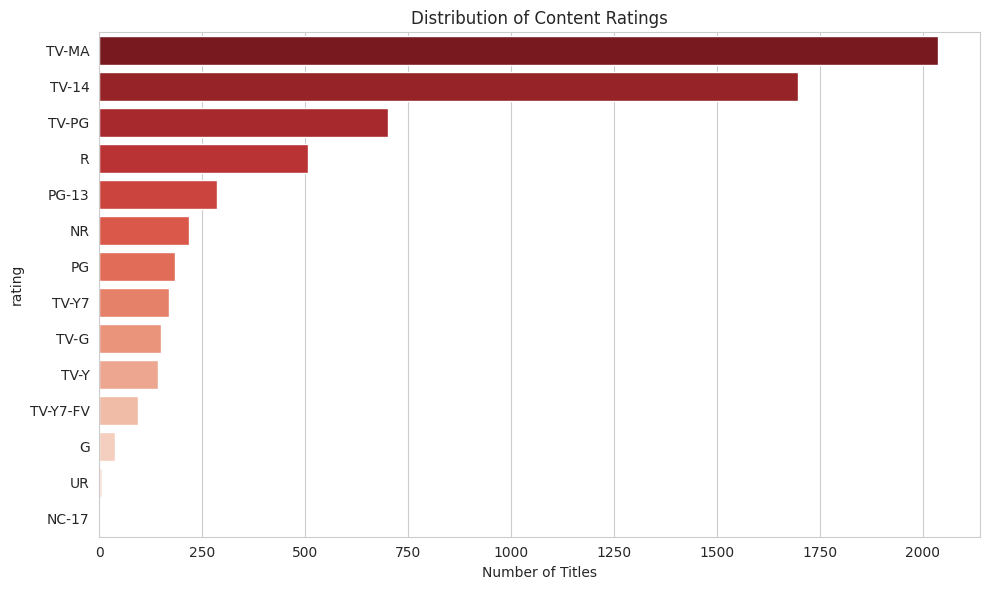

In [22]:
plt.figure(figsize=(10,6))
sns.barplot(x=rating_counts.values, y=rating_counts.index, hue=rating_counts.index,
            palette='Reds_r', legend=False)
plt.title('Distribution of Content Ratings')
plt.xlabel('Number of Titles')
plt.tight_layout()
plt.savefig('../images/rating_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [23]:
adult_ratings = ['TV-MA', 'R', 'NC-17']
kids_ratings = ['TV-Y', 'TV-Y7', 'TV-G', 'G', 'TV-PG', 'PG']
adult_count = df[df['rating'].isin(adult_ratings)].shape[0]
kids_count = df[df['rating'].isin(kids_ratings)].shape[0]
print(f"Adult-rated titles: {adult_count}")
print(f"Kids/family-rated titles: {kids_count}")

Adult-rated titles: 2547
Kids/family-rated titles: 1383


**Insight:** TV-MA and TV-14 are the most common ratings, indicating Netflix's catalog skews toward mature/teen audiences rather than young children.

### 3.5 Director Analysis

In [24]:
directors = df[df['director'] != 'Unknown']['director'].str.split(', ').explode()
top_directors = directors.value_counts().head(10)
top_directors

director
Jan Suter           21
Raúl Campos         19
Jay Karas           14
Marcus Raboy        14
Jay Chapman         12
Martin Scorsese      9
Steven Spielberg     9
Umesh Mehra          8
Shannon Hartman      8
Lance Bangs          8
Name: count, dtype: int64

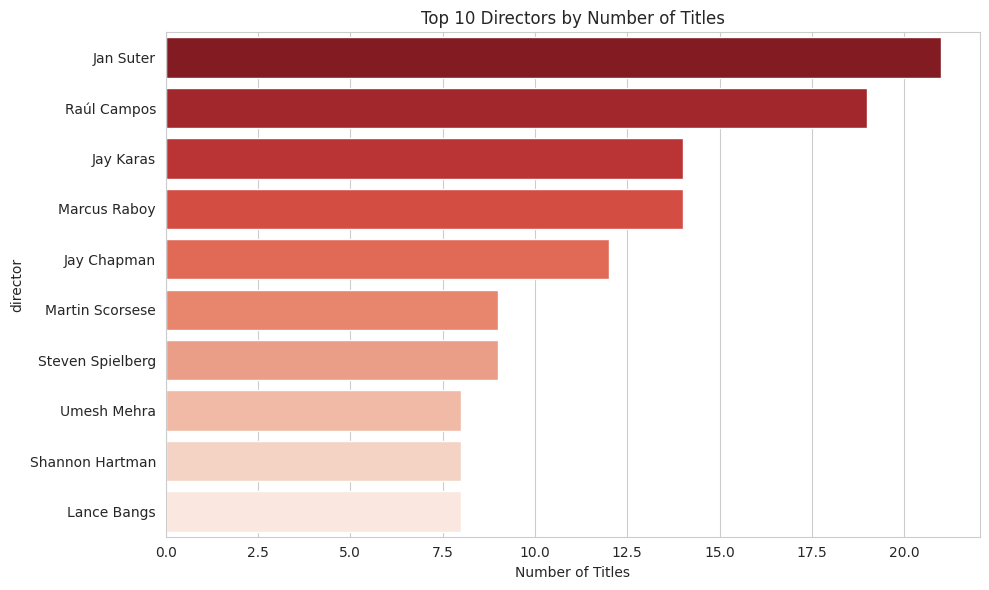

In [25]:
plt.figure(figsize=(10,6))
sns.barplot(x=top_directors.values, y=top_directors.index, hue=top_directors.index,
            palette='Reds_r', legend=False)
plt.title('Top 10 Directors by Number of Titles')
plt.xlabel('Number of Titles')
plt.tight_layout()
plt.savefig('../images/top_directors.png', dpi=150, bbox_inches='tight')
plt.show()

**Insight:** A small group of prolific directors, several specializing in stand-up comedy specials or Bollywood films, account for a disproportionate share of directed titles.

### 3.6 Actor Analysis

In [26]:
actors = df[df['cast'] != 'Unknown']['cast'].str.split(', ').explode()
top_actors = actors.value_counts().head(20)
top_actors

cast
Anupam Kher         33
Shah Rukh Khan      30
Naseeruddin Shah    27
Om Puri             27
Akshay Kumar        26
Yuki Kaji           26
Takahiro Sakurai    25
Paresh Rawal        25
Amitabh Bachchan    24
Boman Irani         23
Andrea Libman       22
Ashleigh Ball       22
John Cleese         22
Kareena Kapoor      19
Tara Strong         18
Vincent Tong        18
Gulshan Grover      18
Erin Fitzgerald     18
Fred Tatasciore     18
Kay Kay Menon       18
Name: count, dtype: int64

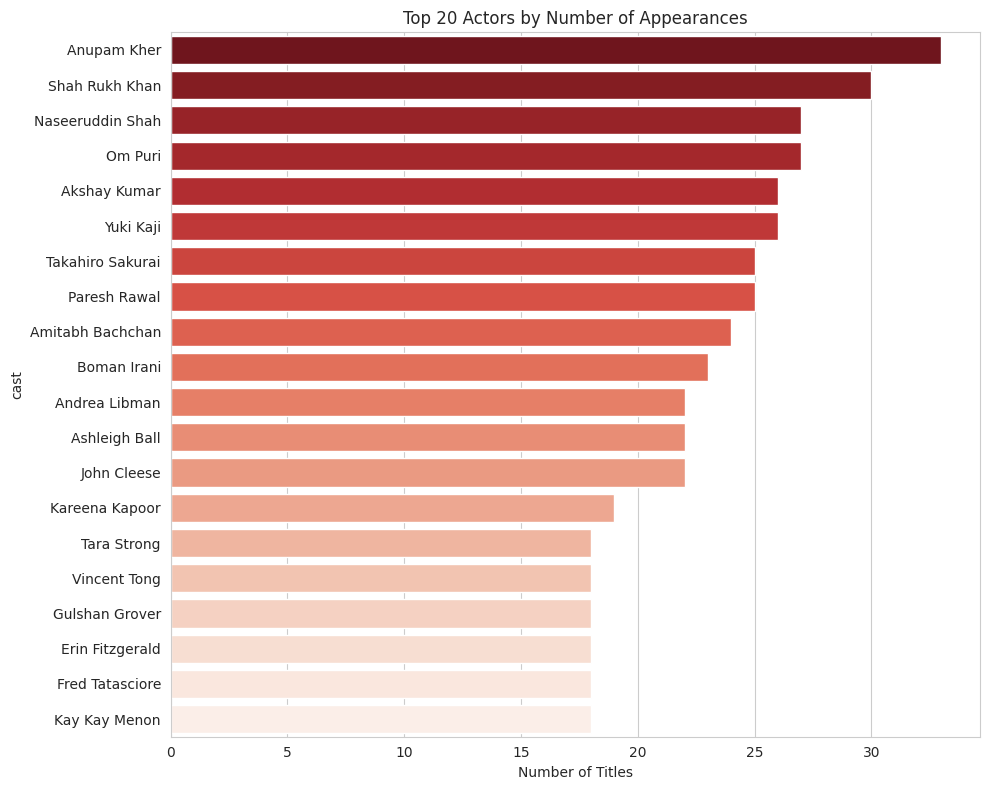

In [27]:
plt.figure(figsize=(10,8))
sns.barplot(x=top_actors.values, y=top_actors.index, hue=top_actors.index,
            palette='Reds_r', legend=False)
plt.title('Top 20 Actors by Number of Appearances')
plt.xlabel('Number of Titles')
plt.tight_layout()
plt.savefig('../images/top_actors.png', dpi=150, bbox_inches='tight')
plt.show()

**Insight:** The most frequently appearing actors are concentrated in Indian and US-produced content, reflecting the two largest content-producing countries in the catalog.

### 3.7 Time Analysis

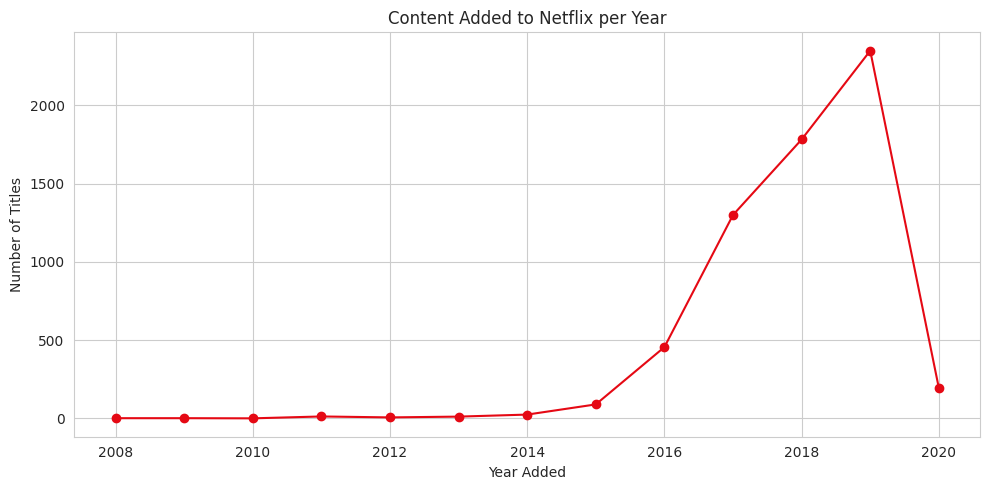

In [28]:
added_per_year = df['year_added'].value_counts().sort_index()
plt.figure(figsize=(10,5))
added_per_year.plot(kind='line', marker='o', color='#E50914')
plt.title('Content Added to Netflix per Year')
plt.xlabel('Year Added')
plt.ylabel('Number of Titles')
plt.tight_layout()
plt.savefig('../images/added_per_year.png', dpi=150, bbox_inches='tight')
plt.show()

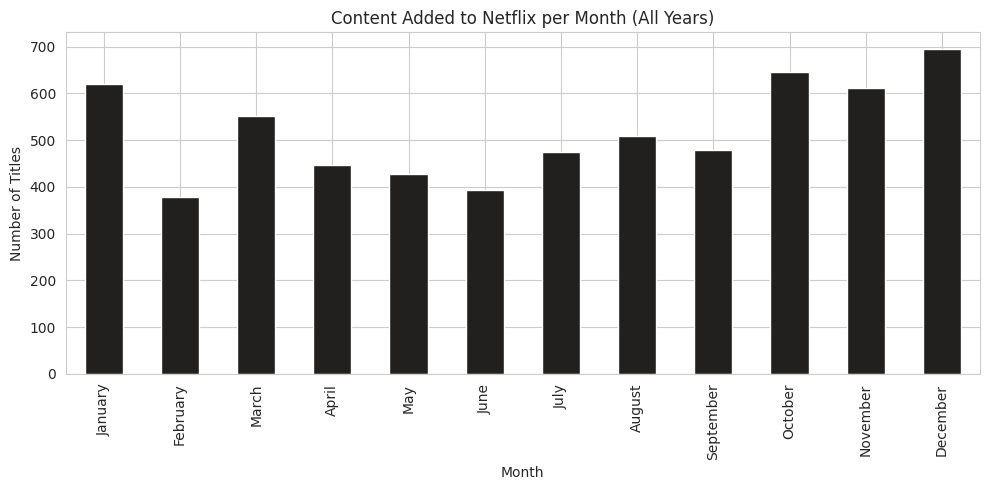

In [29]:
month_order = ['January','February','March','April','May','June','July',
               'August','September','October','November','December']
added_per_month = df['month_added'].value_counts().reindex(month_order)
plt.figure(figsize=(10,5))
added_per_month.plot(kind='bar', color='#221F1F')
plt.title('Content Added to Netflix per Month (All Years)')
plt.xlabel('Month')
plt.ylabel('Number of Titles')
plt.tight_layout()
plt.savefig('../images/added_per_month.png', dpi=150, bbox_inches='tight')
plt.show()

**Insight:** The Netflix library grew explosively between 2016 and 2019, aligning with the company's global expansion; December and January see a slight uptick in additions, likely timed around holiday viewing.

### 3.8 Duration Analysis

In [30]:
movies = df[df['type'] == 'Movie']
tv_shows = df[df['type'] == 'TV Show']

print("Movies — average duration:", round(movies['duration_int'].mean(), 1), "min")
print("Movies — longest:", movies.loc[movies['duration_int'].idxmax(), ['title','duration_int']].to_dict())
print("Movies — shortest:", movies.loc[movies['duration_int'].idxmin(), ['title','duration_int']].to_dict())

Movies — average duration: 99.1 min
Movies — longest: {'title': 'Black Mirror: Bandersnatch', 'duration_int': 312.0}
Movies — shortest: {'title': 'Silent', 'duration_int': 3.0}


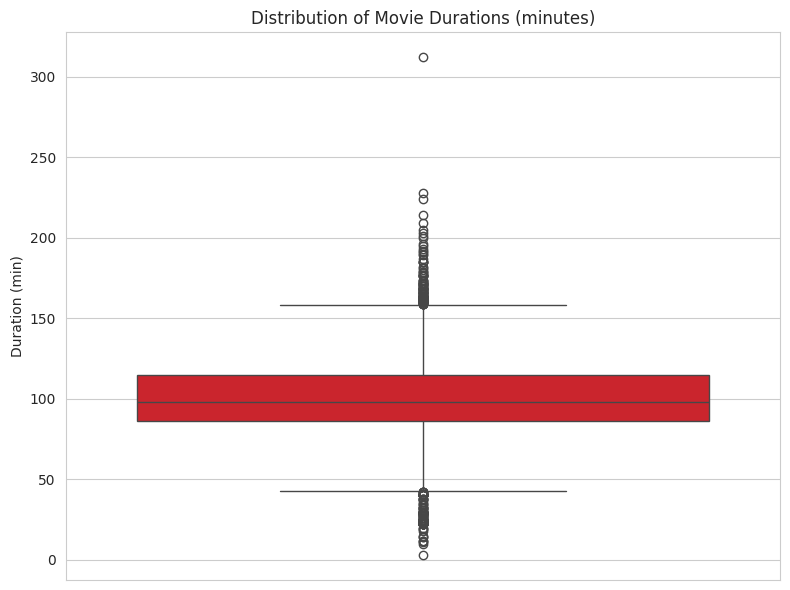

In [31]:
plt.figure(figsize=(8,6))
sns.boxplot(y=movies['duration_int'], color='#E50914')
plt.title('Distribution of Movie Durations (minutes)')
plt.ylabel('Duration (min)')
plt.tight_layout()
plt.savefig('../images/movie_duration_box.png', dpi=150, bbox_inches='tight')
plt.show()

In [32]:
print("TV Shows — average seasons:", round(tv_shows['duration_int'].mean(), 1))
print("TV Shows — most seasons:", tv_shows.loc[tv_shows['duration_int'].idxmax(), ['title','duration_int']].to_dict())

TV Shows — average seasons: 1.8
TV Shows — most seasons: {'title': "Grey's Anatomy", 'duration_int': 15.0}


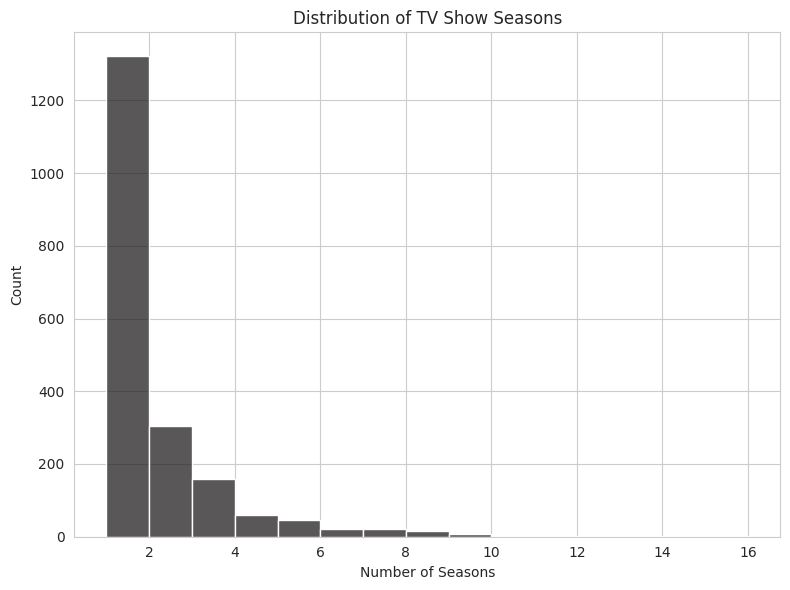

In [33]:
plt.figure(figsize=(8,6))
sns.histplot(tv_shows['duration_int'], bins=range(1,17), color='#221F1F')
plt.title('Distribution of TV Show Seasons')
plt.xlabel('Number of Seasons')
plt.tight_layout()
plt.savefig('../images/tvshow_seasons_hist.png', dpi=150, bbox_inches='tight')
plt.show()

**Insight:** Most movies cluster around 90–100 minutes, the standard feature-length runtime, while the vast majority of TV shows have just 1–2 seasons — suggesting Netflix produces many limited series rather than long-running shows.

### 3.9 Correlation Heatmap

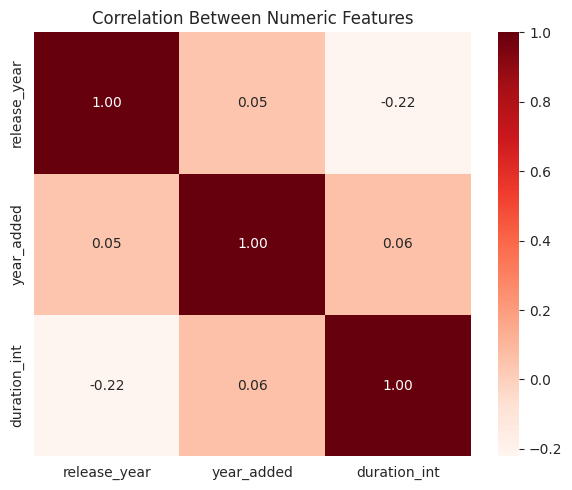

In [34]:
numeric_df = df[['release_year', 'year_added', 'duration_int']].dropna()
plt.figure(figsize=(6,5))
sns.heatmap(numeric_df.corr(), annot=True, cmap='Reds', fmt='.2f')
plt.title('Correlation Between Numeric Features')
plt.tight_layout()
plt.savefig('../images/correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Summary of Key Insights

1. **Movies dominate the catalog** (~70%), with TV Shows a smaller but meaningful share.
2. **The US and India** are by far the largest content-producing countries.
3. **International Movies, Dramas, and Comedies** are the most common genres.
4. **TV-MA and TV-14** are the most frequent ratings — the catalog skews toward mature/teen audiences.
5. **Library growth exploded 2016–2019**, matching Netflix's global expansion and original-content push.
6. **Most movies run ~90–100 minutes**; most TV shows last only 1–2 seasons.

## 5. Next Steps

- Build a genre/country recommendation model.
- Track catalog growth against subscriber/revenue data (external dataset) to correlate content strategy with business outcomes.
- Deploy an interactive dashboard (Plotly Dash / Streamlit) for these findings.
